In [22]:
import numpy as np 
import pandas as pd 
import networkx as nx

import seaborn as sns
import matplotlib.pyplot as plt

from mi_modulo import *

In [23]:
ensayo3_excel = r"C:\Documents\GitHub\Neurociencias-2026-1\S03_datasets\eeg-motor-movementimagery_Ensayo_03.xlsx"
ensayo4_excel = r"C:\Documents\GitHub\Neurociencias-2026-1\S03_datasets\eeg-motor-movementimagery_Ensayo_04.xlsx"
coordenadas_csv = r"C:\Documents\GitHub\Neurociencias-2026-1\S03_datasets\MI_coordinates.csv"

ensayo3_dict = pd.read_excel(ensayo3_excel, sheet_name=None, index_col=0)
ensayo4_dict = pd.read_excel(ensayo4_excel, sheet_name=None, index_col=0)

In [24]:
ensayos3_dfs = lista_dfs(ensayo3_dict)
ensayos4_dfs = lista_dfs(ensayo3_dict)

In [25]:
resultado3_df = capsula(ensayos3_dfs, 0.5, 0.6)
resultado4_df = capsula (ensayos4_dfs, 0.4, 0.7)

NameError: name 'resultado_df' is not defined

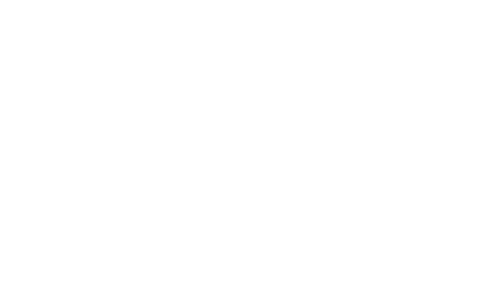

In [26]:
plt.figure(figsize=(5,3))

sns.heatmap(resultado_df)

# Generar estadísticos para decidir umbrales

In [ ]:
ensayos_dfs

th25, th50, th75, promedio, varianza = [], [], [], [], []
mu_sigma = []

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for sujeto in ensayos_dfs:
    # Calculo de estadísticos
    data = sujeto.stack().values
    th25.append(np.percentile(data, 25))
    th50.append(np.percentile(data, 50))
    th75.append(np.percentile(data, 75))
    promedio.append(np.mean(data))
    varianza.append(np.var(data))
    mu_sigma.append(np.mean(data) + np.var(data))
    # Plots
    sns.histplot(sujeto.stack().values, ax=axes[0][0], kde=True)
    sns.ecdfplot(sujeto.stack().values, ax=axes[0][1])
axes[1][0].plot(th25, label='Percentil al 25%')
axes[1][0].plot(th50, label='Percentil al 50%')
axes[1][0].plot(th75, label='Percentil al 75%')
axes[1][0].plot(promedio, label='Media')
axes[1][0].plot(varianza, label='Varianza')
axes[1][0].plot(mu_sigma, label='mu+sigma')
axes[1][0].legend()


In [ ]:
from scipy import stats

In [ ]:
estadisticos_df = pd.DataFrame(columns=['th25', 'th50', 'th75', 'promedio', 'mu_sigma'], 
                               index=['min', 'max', 'mediana', 'cosa_rara'])

columnas = [th25, th50, th75, promedio, mu_sigma]

min_, max_, mediana_, cosa_ = [], [], [], []
for columna in columnas:
    d1, d2, d3, d4 = np.min(columna), np.max(columna), np.median(columna), stats.median_abs_deviation(columna)
    min_.append(d1)
    max_.append(d2)
    mediana_.append(d3)
    cosa_.append(d4)
estadisticos_df.loc['min'] = min_
estadisticos_df.loc['max'] = max_
estadisticos_df.loc['mediana'] = mediana_
estadisticos_df.loc['cosa_rara'] = cosa_

In [ ]:
# test_df = pd.DataFrame(columns=['th25', 'th50', 'th75', 'promedio', 'mu_sigma'], 
#                                index=['min', 'max', 'mediana', 'cosa_rara'])
# estadisticos_ = [th25, th50, th75, promedio, mu_sigma]

# for idx, columna in enumerate(test_df.columns):
#     test_df[columna] = [np.min(estadisticos_[idx]), np.min(estadisticos_[idx]), 
#                         np.median(min(estadisticos_[idx])), stats.median_abs_deviation(estadisticos_[idx])]
# test_df

In [ ]:
estadisticos_df

In [ ]:
# Análisis para valor de umbral al 60% de la población en el ensayo 3
resultado3_df1 = capsula(ensayos3_dfs, 0.2, 0.6)
resultado3_df2 = capsula(ensayos3_dfs, 0.3, 0.6)
resultado3_df3 = capsula(ensayos3_dfs, 0.5, 0.6)
resultado3_df4 = capsula(ensayos3_dfs, 0.6, 0.6)

fig, axes = plt.subplots(2, 2, figsize=(10, 5))

sns.heatmap(resultado3_df1, ax=axes[0, 0])
sns.heatmap(resultado3_df2, ax=axes[0, 1])
sns.heatmap(resultado3_df3, ax=axes[1, 0])
sns.heatmap(resultado3_df4, ax=axes[1, 1])
# plt.title('Mapas de calor para comparativa de umbrales')
axes[0, 0].set_title('umbral=0.2, poblacion>60%', fontsize=10)
fig.suptitle('Análisis para valor de umbral al 60% de la población en el ensayo 3')

In [ ]:
resultado4_df1 = capsula(ensayos4_dfs, 0.2, 0.6)
resultado4_df2 = capsula(ensayos4_dfs, 0.3, 0.6)
resultado4_df3 = capsula(ensayos4_dfs, 0.5, 0.6)
resultado4_df4 = capsula(ensayos4_dfs, 0.6, 0.6)

fig, axes = plt.subplots(2, 2, figsize=(10, 5))

sns.heatmap(resultado4_df1, ax=axes[0, 0])
sns.heatmap(resultado4_df2, ax=axes[0, 1])
sns.heatmap(resultado4_df3, ax=axes[1, 0])
sns.heatmap(resultado4_df4, ax=axes[1, 1])
# plt.title('Mapas de calor para comparativa de umbrales')
axes[0, 0].set_title('umbral=0.2, poblacion>60%', fontsize=10)
fig.suptitle('Análisis para valor de umbral al 60% de la población en el ensayo 4')

# Generación de resultados 

después deñ análaisis realizado, utilizando los mapas de calor, para poder escoger un threshold adecuado y un porcentaje de la población que cumpla dicho; umbral, se procedera a generar los resultados.

resultados a generar 

- grafo 2D
- grafo 3D
- métericas de grafo
- Grafico de comunidades con hub 

In [ ]:
# Convertir de dataframe a grafo
ensayo3_grafo_ = nx.from_pandas_adjacency(resultado3_df3)
ensayo4_grafo_ = nx.from_pandas_adjacency(resultado4_df1)

In [ ]:
# Cálculo de métricas por ensayo
(clust_coeff_3, path_length_3, small_world_sigma_3, communities_3, 
 modularity_3, betwenness_3, global_eff_3, local_eff_3, degree_dict_3) = metricas_grafo(ensayo3_grafo_)

(clust_coeff_4, path_length_4, small_world_sigma_4, communities_4, 
 modularity_4, betwenness_4, global_eff_4, local_eff_4, degree_dict_4) = metricas_grafo(ensayo4_grafo_)

In [ ]:
# Construcción de dataframe de coordenadas
eeg_coords = pd.read_csv(coordenadas_csv)
eeg_coords.set_index("canal", drop=True, inplace=True)

In [ ]:
# Para esto, se necesitan instalar paquetes que no se vieron en clase, por tanto, es opcional
# %matplotlib widget

In [ ]:
%matplotlib widget

In [ ]:
# Grafo de resultados para ensayo 3
hub = betwenness_3[0]

fig = plt.figure(figsize=(10, 8))
axes = [fig.add_subplot(2, 2, 1, projection='3d'), 
        fig.add_subplot(2, 2, 2, projection='3d'), 
        fig.add_subplot(2, 2, 3)]

grafo_comunidades(communities_3, hub, eeg_coords, axes[0])
grafo3D(eeg_coords, hub, axes[1])
ensayo_grafo = grafo2D(resultado3_df3, axes[2])

In [ ]:
# Grafo de resultados para ensayo 3
hub = betwenness_4[0]

fig = plt.figure(figsize=(10, 8))
axes = [fig.add_subplot(2, 2, 1, projection='3d'), 
        fig.add_subplot(2, 2, 2, projection='3d'), 
        fig.add_subplot(2, 2, 3)]

grafo_comunidades(communities_4, hub, eeg_coords, axes[0])
grafo3D(eeg_coords, hub, axes[1])
ensayo_grafo = grafo2D(resultado4_df3, axes[2])

In [ ]:
# Grafo2 para ensayos 3 y 4
hub3 = betwenness_3[0]
hub4 = betwenness_4[0]

fig = plt.figure(figsize=(10, 4))
axes = [fig.add_subplot(1, 2, 1), 
        fig.add_subplot(1, 2, 2)]

ensayo_grafo = grafo2D(resultado3_df3, axes[0])
ensayo_grafo = grafo2D(resultado4_df1, axes[1])

In [27]:
# Grafo3D para ensayos 3 y 4
hub3 = betwenness_3[0]
hub4 = betwenness_4[0]

fig = plt.figure(figsize=(10, 8))
axes = [fig.add_subplot(2, 2, 1, projection='3d'), 
        fig.add_subplot(2, 2, 2, projection='3d')]

grafo3D(eeg_coords, hub3, axes[0])
grafo3D(eeg_coords, hub4, axes[1])

NameError: name 'betwenness_3' is not defined

In [28]:
# Comunidades para ensayos 3 y 4
hub3 = betwenness_3[0]
hub4 = betwenness_4[0]

fig = plt.figure(figsize=(10, 8))
axes = [fig.add_subplot(2, 2, 1, projection='3d'), 
        fig.add_subplot(2, 2, 2, projection='3d')]

grafo_comunidades(communities_3, hub3, eeg_coords, axes[0])
grafo_comunidades(communities_4, hub4, eeg_coords, axes[1])

NameError: name 'betwenness_3' is not defined

# Leer datos generar lista de dataframes compactar a 1 dataframe hacer análisis sobre umbrales por ensayo analizamos resultado con mapa de calor observamos resultado en grafo 2D observamos resultado en grafo 3D

Conocimiento previo, expertice Análisis de literatura Lógica

In [29]:
import importlib
import mi_modulo 

# Esta línea es para que cargue nuevamente el coso este 
importlib.reload(mi_modulo)

<module 'mi_modulo' from 'C:\\Users\\Ana-Sophia Redstone\\Documents\\GitHub\\Neurociencias-2026-1\\S04_parciales\\examen parcial 3 Redstone\\mi_modulo.py'>

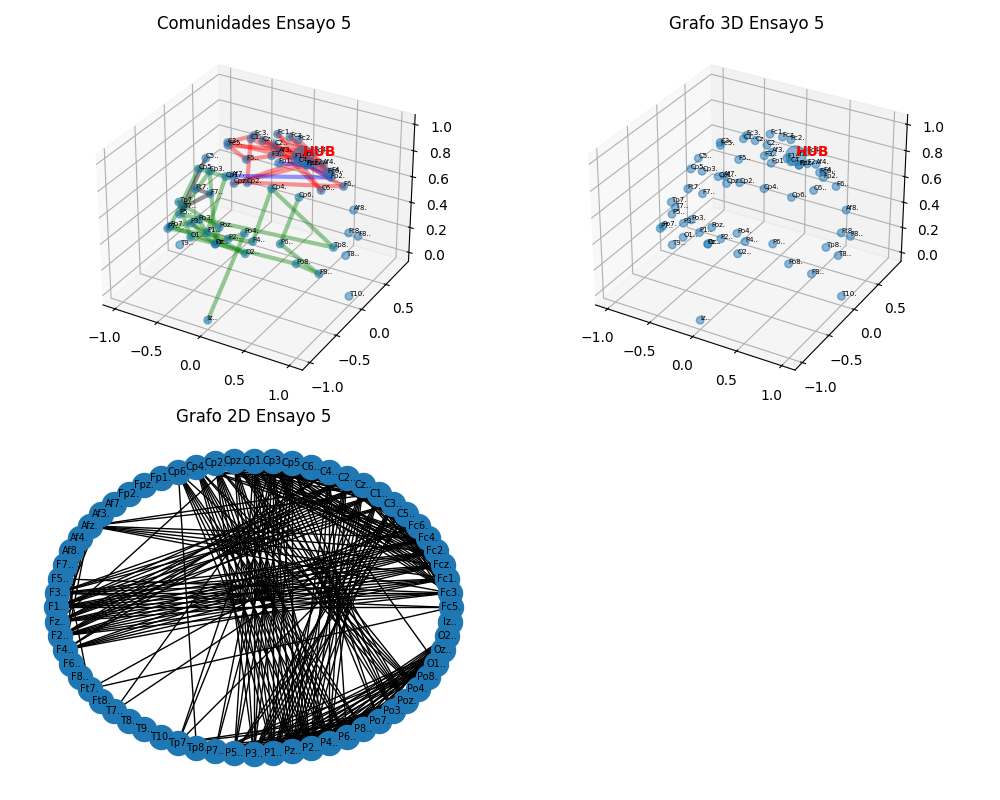

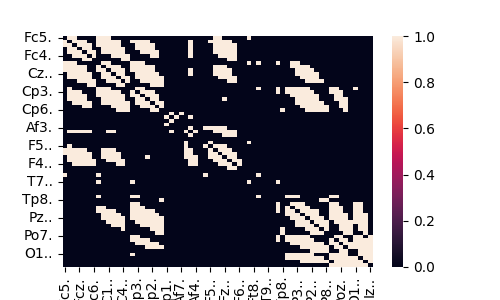

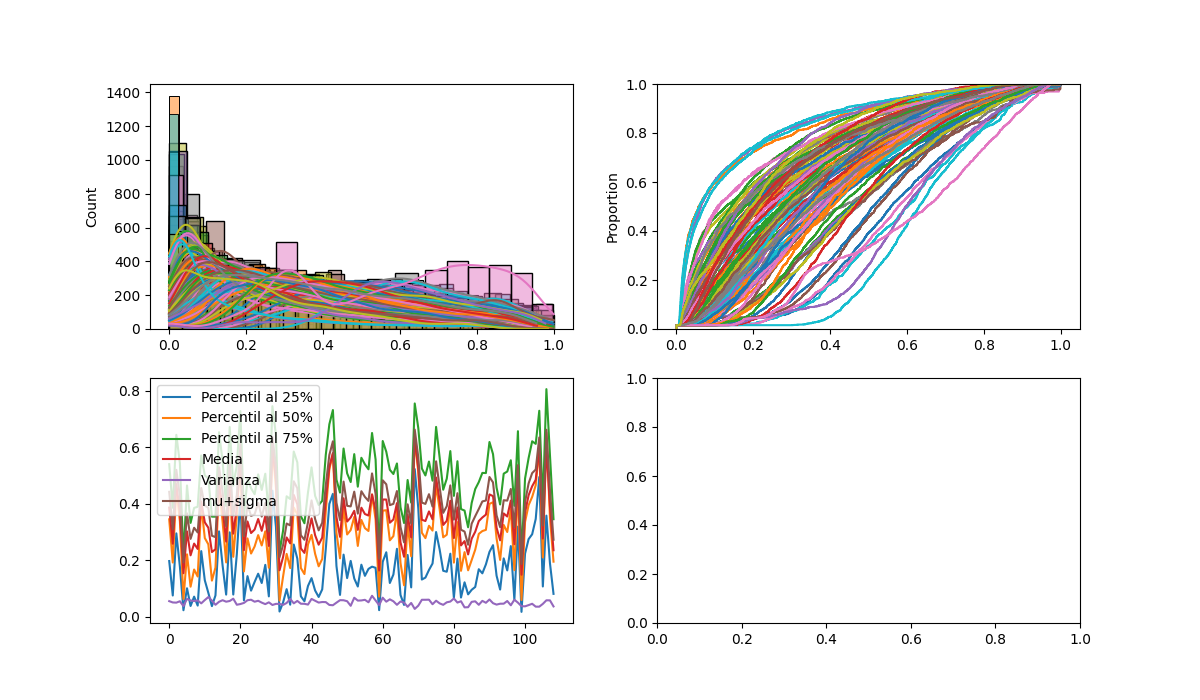

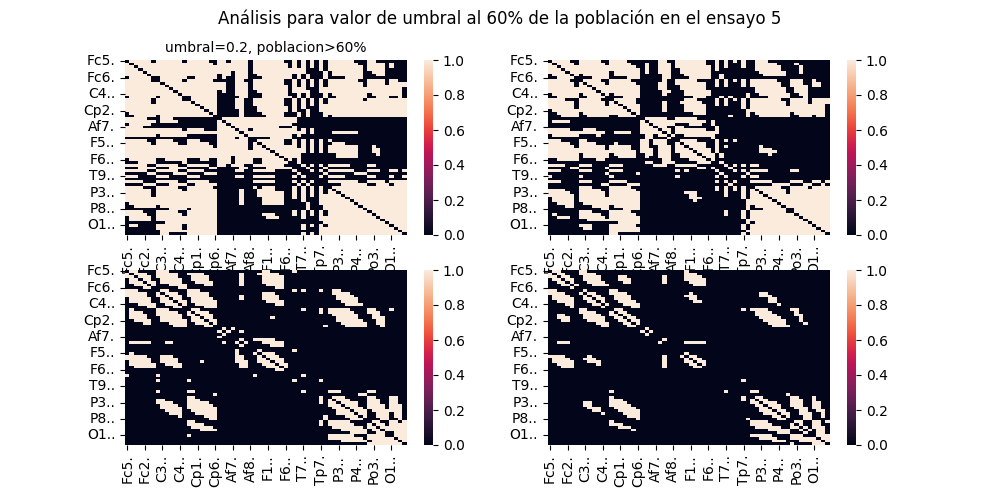

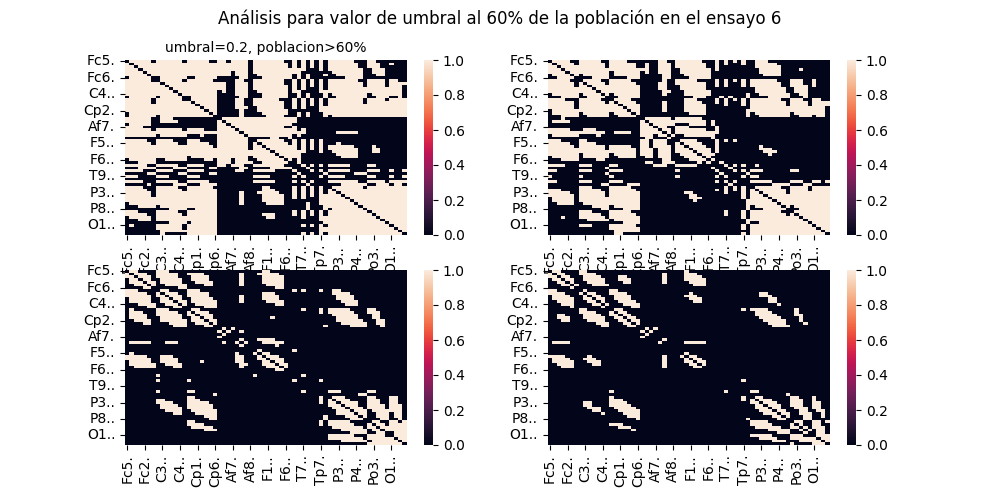

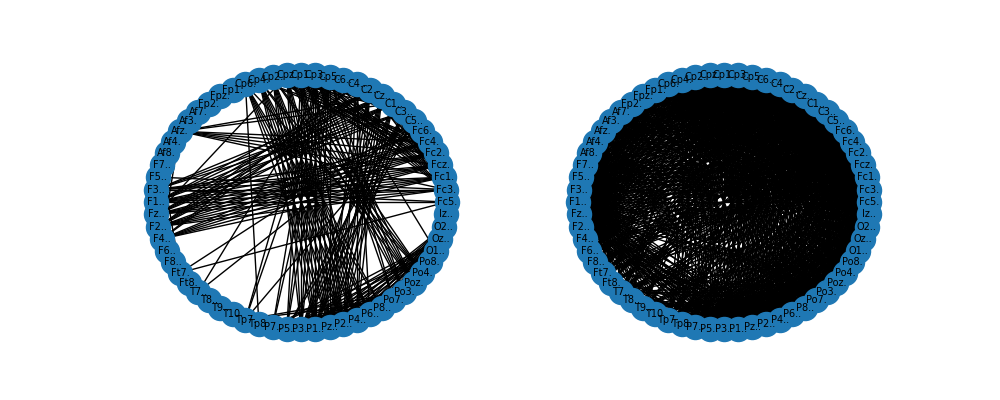

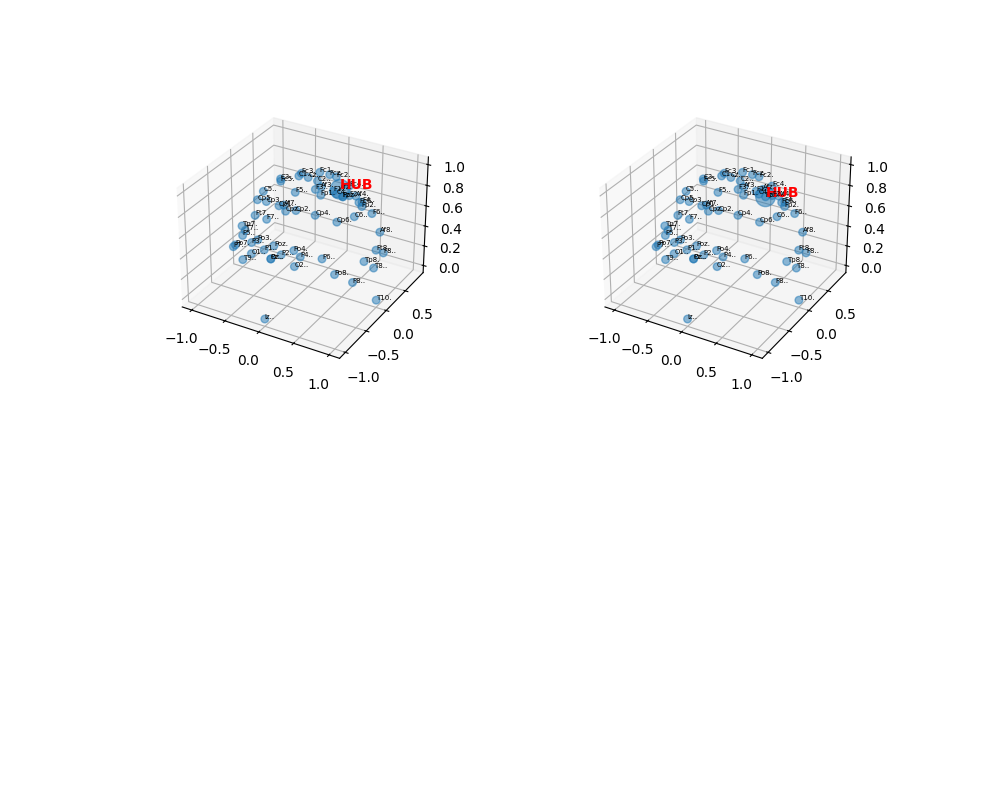

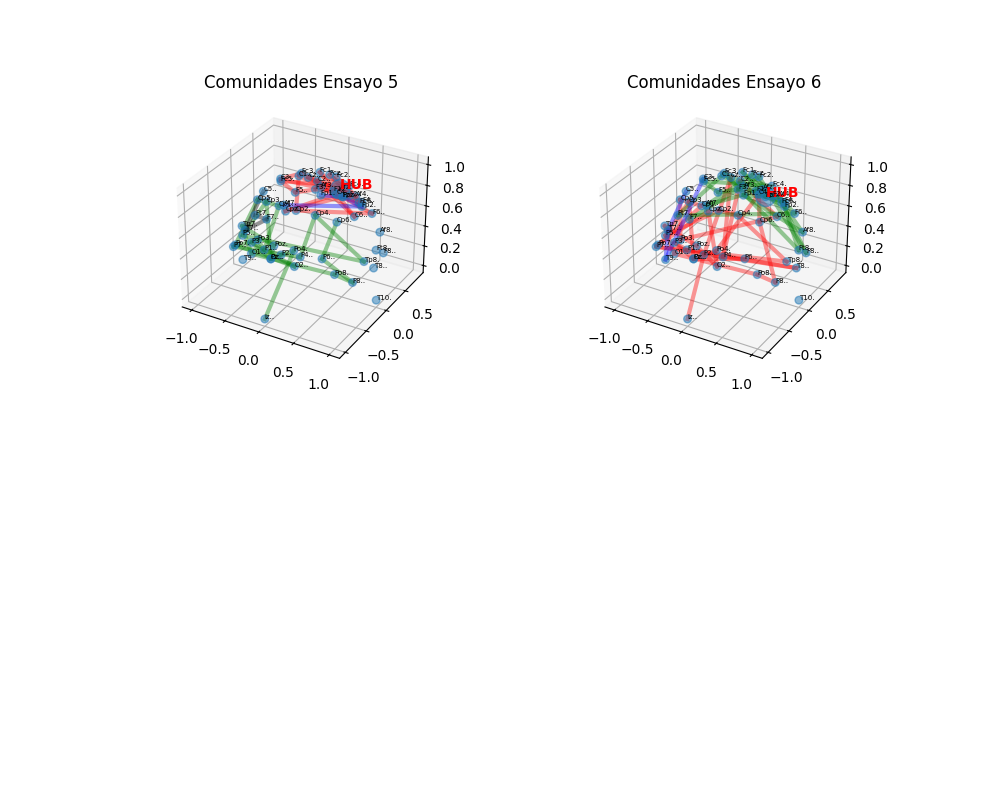

In [30]:
import numpy as np 
import pandas as pd 
import networkx as nx

import seaborn as sns
import matplotlib.pyplot as plt

from mi_modulo import * 

ensayo5_excel = r"C:\Documents\GitHub\Neurociencias-2026-1\S03_datasets\eeg-motor-movementimagery_Ensayo_05.xlsx"
ensayo6_excel = r"C:\Documents\GitHub\Neurociencias-2026-1\S03_datasets\eeg-motor-movementimagery_Ensayo_06.xlsx"
coordenadas_csv = r"C:\Documents\GitHub\Neurociencias-2026-1\S03_datasets\MI_coordinates.csv"

ensayo5_dict = pd.read_excel(ensayo5_excel, sheet_name=None, index_col=0)
ensayo6_dict = pd.read_excel(ensayo6_excel, sheet_name=None, index_col=0)

ensayos5_dfs = lista_dfs(ensayo5_dict)
ensayos6_dfs = lista_dfs(ensayo6_dict)

resultado5_df = capsula(ensayos5_dfs, 0.5, 0.6)
resultado6_df = capsula(ensayos6_dfs, 0.4, 0.7)

plt.figure(figsize=(5,3))
sns.heatmap(resultado5_df)


ensayos_dfs = ensayos5_dfs

th25, th50, th75, promedio, varianza = [], [], [], [], []
mu_sigma = []

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for sujeto in ensayos_dfs:
    # Calculo de estadísticos
    data = sujeto.stack().values
    th25.append(np.percentile(data, 25))
    th50.append(np.percentile(data, 50))
    th75.append(np.percentile(data, 75))
    promedio.append(np.mean(data))
    varianza.append(np.var(data))
    mu_sigma.append(np.mean(data) + np.var(data))
    # Plots
    sns.histplot(sujeto.stack().values, ax=axes[0][0], kde=True)
    sns.ecdfplot(sujeto.stack().values, ax=axes[0][1])
axes[1][0].plot(th25, label='Percentil al 25%')
axes[1][0].plot(th50, label='Percentil al 50%')
axes[1][0].plot(th75, label='Percentil al 75%')
axes[1][0].plot(promedio, label='Media')
axes[1][0].plot(varianza, label='Varianza')
axes[1][0].plot(mu_sigma, label='mu+sigma')
axes[1][0].legend()

from scipy import stats

estadisticos_df = pd.DataFrame(columns=['th25', 'th50', 'th75', 'promedio', 'mu_sigma'], 
                               index=['min', 'max', 'mediana', 'cosa_rara'])

columnas = [th25, th50, th75, promedio, mu_sigma]

min_, max_, mediana_, cosa_ = [], [], [], []
for columna in columnas:
    d1, d2, d3, d4 = np.min(columna), np.max(columna), np.median(columna), stats.median_abs_deviation(columna)
    min_.append(d1)
    max_.append(d2)
    mediana_.append(d3)
    cosa_.append(d4)
estadisticos_df.loc['min'] = min_
estadisticos_df.loc['max'] = max_
estadisticos_df.loc['mediana'] = mediana_
estadisticos_df.loc['cosa_rara'] = cosa_

estadisticos_df

# Análisis para valor de umbral al 60% de la población en el ensayo 5
resultado5_df1 = capsula(ensayos5_dfs, 0.2, 0.6)
resultado5_df2 = capsula(ensayos5_dfs, 0.3, 0.6)
resultado5_df3 = capsula(ensayos5_dfs, 0.5, 0.6)
resultado5_df4 = capsula(ensayos5_dfs, 0.6, 0.6)

fig, axes = plt.subplots(2, 2, figsize=(10, 5))

sns.heatmap(resultado5_df1, ax=axes[0, 0])
sns.heatmap(resultado5_df2, ax=axes[0, 1])
sns.heatmap(resultado5_df3, ax=axes[1, 0])
sns.heatmap(resultado5_df4, ax=axes[1, 1])
# plt.title('Mapas de calor para comparativa de umbrales')
axes[0, 0].set_title('umbral=0.2, poblacion>60%', fontsize=10)
fig.suptitle('Análisis para valor de umbral al 60% de la población en el ensayo 5')

# Análisis para valor de umbral al 60% de la población en el ensayo 6
resultado6_df1 = capsula(ensayos6_dfs, 0.2, 0.6)
resultado6_df2 = capsula(ensayos6_dfs, 0.3, 0.6)
resultado6_df3 = capsula(ensayos6_dfs, 0.5, 0.6)
resultado6_df4 = capsula(ensayos6_dfs, 0.6, 0.6)

fig, axes = plt.subplots(2, 2, figsize=(10, 5))

sns.heatmap(resultado6_df1, ax=axes[0, 0])
sns.heatmap(resultado6_df2, ax=axes[0, 1])
sns.heatmap(resultado6_df3, ax=axes[1, 0])
sns.heatmap(resultado6_df4, ax=axes[1, 1])
# plt.title('Mapas de calor para comparativa de umbrales')
axes[0, 0].set_title('umbral=0.2, poblacion>60%', fontsize=10)
fig.suptitle('Análisis para valor de umbral al 60% de la población en el ensayo 6')

# Convertir de dataframe a grafo
ensayo5_grafo_ = nx.from_pandas_adjacency(resultado5_df3)
ensayo6_grafo_ = nx.from_pandas_adjacency(resultado6_df1)

# Cálculo de métricas por ensayo
(clust_coeff_5, path_length_5, small_world_sigma_5, communities_5, 
 modularity_5, betwenness_5, global_eff_5, local_eff_5, degree_dict_5) = metricas_grafo(ensayo5_grafo_)

(clust_coeff_6, path_length_6, small_world_sigma_6, communities_6, 
 modularity_6, betwenness_6, global_eff_6, local_eff_6, degree_dict_6) = metricas_grafo(ensayo6_grafo_)

# Construcción de dataframe de coordenadas
eeg_coords = pd.read_csv(coordenadas_csv)
eeg_coords.set_index("canal", drop=True, inplace=True)

%matplotlib widget

# Grafo de resultados para ensayo 5
hub = betwenness_5[0] 

fig = plt.figure(figsize=(10, 8))
# Aquí se crean 3 ejes: 2 en 3D y 1 en 2D
axes = [fig.add_subplot(2, 2, 1, projection='3d'), 
        fig.add_subplot(2, 2, 2, projection='3d'), 
        fig.add_subplot(2, 2, 3)]


grafo_comunidades(communities_5, hub, eeg_coords, axes[0], titulo='Comunidades Ensayo 5')

# vamo a ver si funciona 

grafo3D(eeg_coords, hub, axes[1]) 
axes[1].set_title('Grafo 3D Ensayo 5') 

# 'resultado5_df3' es la matriz de adyacencia binarizada
ensayo_grafo = grafo2D(resultado5_df3, axes[2]) 
axes[2].set_title('Grafo 2D Ensayo 5') 

plt.tight_layout() # Para ajustar los subplots y que no se superpongan
plt.show() # Mostrar la figura

# Grafo2 para ensayos 5 y 6
hub5 = betwenness_5[0]
hub6 = betwenness_6[0]

fig = plt.figure(figsize=(10, 4))
axes = [fig.add_subplot(1, 2, 1), 
        fig.add_subplot(1, 2, 2)]

ensayo_grafo = grafo2D(resultado5_df3, axes[0])
ensayo_grafo = grafo2D(resultado6_df1, axes[1])

# Grafo3D para ensayos 5 y 6
hub5 = betwenness_5[0]
hub6 = betwenness_6[0]

fig = plt.figure(figsize=(10, 8))
axes = [fig.add_subplot(2, 2, 1, projection='3d'), 
        fig.add_subplot(2, 2, 2, projection='3d')]

grafo3D(eeg_coords, hub5, axes[0])
grafo3D(eeg_coords, hub6, axes[1])

# Comunidades para ensayos 5 y 6
hub5 = betwenness_5[0]
hub6 = betwenness_6[0]

fig = plt.figure(figsize=(10, 8))
axes = [fig.add_subplot(2, 2, 1, projection='3d'), 
        fig.add_subplot(2, 2, 2, projection='3d')]

# CAMBIADO: Comunidades para Ensayo 5
grafo_comunidades(communities_5, hub5, eeg_coords, axes[0], titulo='Comunidades Ensayo 5') 

# CAMBIADO: Comunidades para Ensayo 6
grafo_comunidades(communities_6, hub6, eeg_coords, axes[1], titulo='Comunidades Ensayo 6')

## Conclusión del análisis

Se realizó el análisis de los ensayos 5 y 6, que el objetivo de la tarea era  el abrir y cerrar ambos pies o manos e imaginar los movimientos, respectivamente.En ambos casos encontramos dos comunidades, una frontal y otra en áreas occipitales. 

A partir de esto podemos concluir que, sabiendo que las áreas motoras y frontales son muy importantes el inicio del movimiento y para llevarlo acabo, la comunidad de color verde/azul es la que tiene más desarrollo. También importante mencionar que se observa un hub en regiones frontales.